In [1]:
from src.pykingenie import KineticsAnalyzer
from src.pykingenie import OctetExperiment
from src.pykingenie.utils.plotting import plot_traces_all,plot_association_dissociation
import os
import numpy as np

In [2]:
folder = "/Users/oburastero/Desktop/arise/bli_learn/ida/"
frd_files = os.listdir(folder)

frd_files = [f for f in frd_files if f.endswith(".frd")]
frd_files.sort()
frd_files_full_path = [os.path.join(folder, f) for f in frd_files]

frd_files_sample = frd_files_full_path[:8]
frd_files_ctrl   = frd_files_full_path[23]

/var/folders/pt/zh1pzbvn22x3n2k8bzlmqsm80000gr/T/ipykernel_8796/582244965.py:15: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



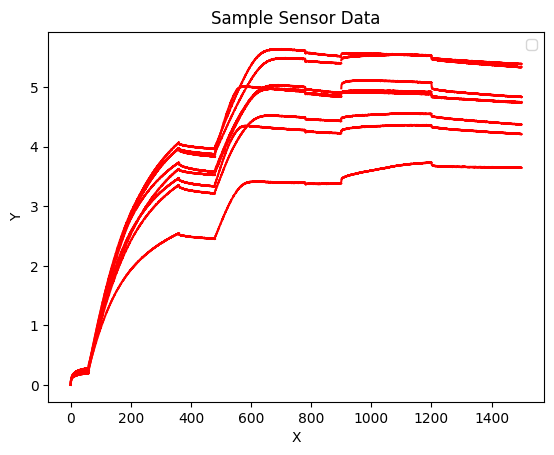

300 300
1500 1500
600 600
1500 1500
600 600
1500 1500
1500 1500
300 300
1500 1500
600 600
1500 1500
600 600
1500 1500
1500 1500
300 300
1500 1500
600 600
1500 1500
600 600
1500 1500
1500 1500
300 300
1500 1500
600 600
1500 1500
600 600
1500 1500
1500 1500
300 300
1500 1500
600 600
1500 1500
600 600
1500 1500
1500 1500
300 300
1500 1500
600 600
1500 1500
600 600
1500 1500
1500 1500
300 300
1500 1500
600 600
1500 1500
600 600
1500 1500
1500 1500
300 300
1500 1500
600 600
1500 1500
600 600
1500 1500
1500 1500


/var/folders/pt/zh1pzbvn22x3n2k8bzlmqsm80000gr/T/ipykernel_8796/582244965.py:42: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



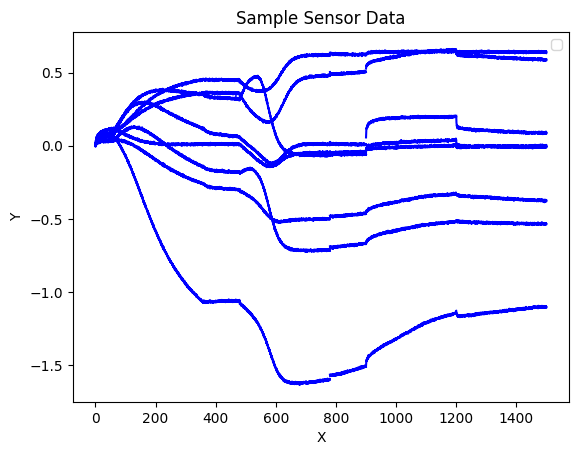

In [ ]:
bli_sample = OctetExperiment("sample")
bli_ctrl = OctetExperiment("control")

bli_sample.read_sensor_data(frd_files_sample)
bli_ctrl.read_sensor_data(frd_files_ctrl)

import matplotlib.pyplot as plt
# plot y versus x for sample 
for i in range(len(bli_sample.xs)):
    for j in range(len(bli_sample.xs[i])):
        plt.plot(bli_sample.xs[i][j], bli_sample.ys[i][j],color='red')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Sample Sensor Data')
plt.legend()
plt.show()

sensors_sample = bli_sample.sensor_names

for i, sensor_name in enumerate(sensors_sample):

    for j in range(len(bli_sample.xs[i])):

        y_sample = bli_sample.ys[i][j]
        y_ctrl = bli_ctrl.ys[0][j]

        if len(y_sample) != len(y_ctrl):
            print(f"Length mismatch for sensor {sensor_name}, sample index {i}, repetition {j}")
            continue

        bli_sample.ys[i][j] -= bli_ctrl.ys[0][j]

import matplotlib.pyplot as plt
# plot y versus x for sample 
for i in range(len(bli_sample.xs)):
    for j in range(len(bli_sample.xs[i])):
        plt.plot(bli_sample.xs[i][j], bli_sample.ys[i][j],color='b')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Sample Sensor Data')
plt.legend()

# save figures
plt.savefig('sample_sensor_data.png')

plt.show()




In [4]:
bli_sample = OctetExperiment("sample")
bli_ctrl = OctetExperiment("control")

bli_sample.read_sensor_data(frd_files_sample)
bli_ctrl.read_sensor_data(frd_files_ctrl)

subtract_ctrl = True
alig_assoc = True
alig_diss = True
subtract_avg = True


pk = KineticsAnalyzer()
pk.add_experiment(bli_sample,"sample")

legends_df = pk.get_legends_table()

fig = plot_traces_all(pk,legends_df,line_width=0,marker_size=10)
fig.write_html("traces_0.html")

i = 0
if subtract_ctrl:
    bli_sample.find_experiments_compatibility(bli_ctrl)
    bli_sample.subtract_experiment(bli_ctrl)    

    pk = KineticsAnalyzer()
    pk.add_experiment(bli_sample,"sample")

    legends_df = pk.get_legends_table()

    fig = plot_traces_all(pk,legends_df,line_width=0,marker_size=10)

    i += 1
    fig.write_html(f"traces_{i}_ctrl_sub.html")

if alig_assoc:
    bli_sample.align_association(npoints=10)

    pk = KineticsAnalyzer()
    pk.add_experiment(bli_sample,"sample")

    legends_df = pk.get_legends_table()

    fig = plot_traces_all(pk,legends_df,line_width=0,marker_size=10)

    i += 1
    fig.write_html(f"traces_{i}_alig_assoc.html")

if subtract_avg:
    sensor_names = bli_sample.sensor_names
    last_two_sensors = sensor_names[-1:]
    print(last_two_sensors)
    bli_sample.average(last_two_sensors, new_sensor_name="Avg")
    avg_sensor = bli_sample.sensor_names[-1]

    sensor_names = bli_sample.sensor_names
    bli_sample.subtraction(sensor_names,avg_sensor)

    pk = KineticsAnalyzer()
    pk.add_experiment(bli_sample,"sample")

    legends_df = pk.get_legends_table()

    fig = plot_traces_all(pk,legends_df,line_width=0,marker_size=10)

    i += 1
    fig.write_html(f"traces_{i}_subtract_avg.html")

if alig_diss:
    sensor_names = bli_sample.sensor_names
    bli_sample.assoc_inter_step_correction(sensor_names,npoints=2)

    pk = KineticsAnalyzer()
    pk.add_experiment(bli_sample,"sample")

    legends_df = pk.get_legends_table()

    fig = plot_traces_all(pk,legends_df,line_width=0,marker_size=10)

    i += 1
    fig.write_html(f"traces_{i}_alig_diss.html")


RuntimeError: Experiments have different number of sensors

In [ ]:
pk = KineticsAnalyzer()
pk.add_experiment(bli_sample,"sample")
#pk.add_experiment(bli_ctrl,"control")

legends_df = pk.get_legends_table()

fig = plot_traces_all(pk,legends_df,line_width=0,marker_size=10)
fig.write_html("traces_all.html")

pk.merge_ligand_conc_df()
df = pk.combined_ligand_conc_df

df

In [ ]:
#set concentration to one in second column of df
df.iloc[:,1] = 1
# set to False fourth column, last row
df.iloc[-1,3] = False

df

In [ ]:
pk.init_fittings()
pk.generate_fittings(df)

In [ ]:
plot_association_dissociation(pk,max_points_per_plot=1e6)